In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

In [3]:
# load data set
df=pd.read_csv(r"C:\Users\hp\OneDrive\Desktop\Cancer_Project\data\raw\cancer_reg.csv",encoding="latin1")
df.head()


,avgAnnCount,avgDeathsPerYear,TARGET_deathRate,incidenceRate,medIncome,popEst2015,povertyPercent,studyPerCap,binnedInc,MedianAge,...,PctPrivateCoverageAlone,PctEmpPrivCoverage,PctPublicCoverage,PctPublicCoverageAlone,PctWhite,PctBlack,PctAsian,PctOtherRace,PctMarriedHouseholds,BirthRate
0,1397.0,469,164.9,489.8,61898,260131,11.2,499.748204,"(61494.5, 125635]",39.3,...,NaN,41.6,32.9,14.0,81.780529,2.594728,4.821857,1.843479,52.856076,6.118831
1,173.0,70,161.3,411.6,48127,43269,18.6,23.111234,"(48021.6, 51046.4]",33.0,...,53.8,43.6,31.1,15.3,89.228509,0.969102,2.246233,3.741352,45.372500,4.333096
2,102.0,50,174.7,349.7,49348,21026,14.6,47.560164,"(48021.6, 51046.4]",45.0,...,43.5,34.9,42.1,21.1,90.922190,0.739673,0.465898,2.747358,54.444868,3.729488
3,427.0,202,194.8,430.4,44243,75882,17.1,342.637253,"(42724.4, 45201]",42.8,...,40.3,35.0,45.3,25.0,91.744686,0.782626,1.161359,1.362643,51.021514,4.603841
4,57.0,26,144.4,350.1,49955,10321,12.5,0.000000,"(48021.6, 51046.4]",48.3,...,43.9,35.1,44.0,22.7,94.104024,0.270192,0.665830,0.492135,54.027460,6.796657


#### Data Cleaning

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3047 entries, 0 to 3046
Data columns (total 34 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   avgAnnCount              3047 non-null   float64
 1   avgDeathsPerYear         3047 non-null   int64  
 2   TARGET_deathRate         3047 non-null   float64
 3   incidenceRate            3047 non-null   float64
 4   medIncome                3047 non-null   int64  
 5   popEst2015               3047 non-null   int64  
 6   povertyPercent           3047 non-null   float64
 7   studyPerCap              3047 non-null   float64
 8   binnedInc                3047 non-null   object 
 9   MedianAge                3047 non-null   float64
 10  MedianAgeMale            3047 non-null   float64
 11  MedianAgeFemale          3047 non-null   float64
 12  Geography                3047 non-null   object 
 13  AvgHouseholdSize         3047 non-null   float64
 14  PercentMarried          

In [5]:
df.isna().sum()

avgAnnCount                   0
avgDeathsPerYear              0
TARGET_deathRate              0
incidenceRate                 0
medIncome                     0
popEst2015                    0
povertyPercent                0
studyPerCap                   0
binnedInc                     0
MedianAge                     0
MedianAgeMale                 0
MedianAgeFemale               0
Geography                     0
AvgHouseholdSize              0
PercentMarried                0
PctNoHS18_24                  0
PctHS18_24                    0
PctSomeCol18_24            2285
PctBachDeg18_24               0
PctHS25_Over                  0
PctBachDeg25_Over             0
PctEmployed16_Over          152
PctUnemployed16_Over          0
PctPrivateCoverage            0
PctPrivateCoverageAlone     609
PctEmpPrivCoverage            0
PctPublicCoverage             0
PctPublicCoverageAlone        0
PctWhite                      0
PctBlack                      0
PctAsian                      0
PctOther

In [6]:
df.drop(columns="PctSomeCol18_24",inplace=True)

In [7]:
df.isna().sum()

avgAnnCount                  0
avgDeathsPerYear             0
TARGET_deathRate             0
incidenceRate                0
medIncome                    0
popEst2015                   0
povertyPercent               0
studyPerCap                  0
binnedInc                    0
MedianAge                    0
MedianAgeMale                0
MedianAgeFemale              0
Geography                    0
AvgHouseholdSize             0
PercentMarried               0
PctNoHS18_24                 0
PctHS18_24                   0
PctBachDeg18_24              0
PctHS25_Over                 0
PctBachDeg25_Over            0
PctEmployed16_Over         152
PctUnemployed16_Over         0
PctPrivateCoverage           0
PctPrivateCoverageAlone    609
PctEmpPrivCoverage           0
PctPublicCoverage            0
PctPublicCoverageAlone       0
PctWhite                     0
PctBlack                     0
PctAsian                     0
PctOtherRace                 0
PctMarriedHouseholds         0
BirthRat

In [8]:
# check PctEmployed16_Over columns
# check datatype
print("datatype:",df['PctEmployed16_Over'].dtype)
# check missing value
print("missing value:",df['PctEmployed16_Over'].isna().sum())
print("-"*50)
# check missing percentage
missing_count=df['PctEmployed16_Over'].isna().sum()
missing_percent = (missing_count / len(df)) * 100
print("missing_percent:",missing_percent)

# fill missing value with median 
df['PctEmployed16_Over']=df['PctEmployed16_Over'].fillna(df['PctEmployed16_Over'].median())
print("after fill missing value:",df['PctEmployed16_Over'])

datatype: float64
missing value: 152
--------------------------------------------------
missing_percent: 4.98851329176239
after fill missing value: 0       51.9
1       55.9
2       45.9
3       48.3
4       48.2
        ... 
3042    51.7
3043    70.1
3044    64.8
3045    54.5
3046    48.8
Name: PctEmployed16_Over, Length: 3047, dtype: float64


In [9]:
df["PctEmployed16_Over"].isna().sum()

np.int64(0)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
# check PctPrivateCoverageAlone this columns
print("datatype:",df['PctPrivateCoverageAlone'].dtype)
# check missing value
print("missing value:",df['PctPrivateCoverageAlone'].isna().sum())
# check percentage of missing value
print("missing per:",((df['PctPrivateCoverageAlone'].isna().sum())/len(df))*100)

# fill missing value using median
df['PctPrivateCoverageAlone']=df['PctPrivateCoverageAlone'].fillna(df['PctPrivateCoverageAlone'].median())
print(df['PctPrivateCoverageAlone'])

datatype: float64
missing value: 609
missing per: 19.986872333442733
0       48.7
1       53.8
2       43.5
3       40.3
4       43.9
        ... 
3042    54.9
3043    53.3
3044    52.6
3045    56.3
3046    60.3
Name: PctPrivateCoverageAlone, Length: 3047, dtype: float64


In [15]:
# Statistical Summary
df.describe()

,avgAnnCount,avgDeathsPerYear,TARGET_deathRate,incidenceRate,medIncome,popEst2015,povertyPercent,studyPerCap,MedianAge,MedianAgeMale,...,PctPrivateCoverageAlone,PctEmpPrivCoverage,PctPublicCoverage,PctPublicCoverageAlone,PctWhite,PctBlack,PctAsian,PctOtherRace,PctMarriedHouseholds,BirthRate
count,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3.047000e+03,3047.000000,3047.000000,3047.000000,3047.000000,...,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000,3047.000000
mean,606.338544,185.965868,178.664063,448.268586,47063.281917,1.026374e+05,16.878175,155.399415,45.272333,39.570725,...,48.502987,41.196324,36.252642,19.240072,83.645286,9.107978,1.253965,1.983523,51.243872,5.640306
std,1416.356223,504.134286,27.751511,54.560733,12040.090836,3.290592e+05,6.409087,529.628366,45.304480,5.226017,...,9.019423,9.447687,7.841741,6.113041,16.380025,14.534538,2.610276,3.517710,6.572814,1.985816
min,6.000000,3.000000,59.700000,201.300000,22640.000000,8.270000e+02,3.200000,0.000000,22.300000,22.400000,...,15.700000,13.500000,11.200000,2.600000,10.199155,0.000000,0.000000,0.000000,22.992490,0.000000
25%,76.000000,28.000000,161.200000,420.300000,38882.500000,1.168400e+04,12.150000,0.000000,37.700000,36.350000,...,43.100000,34.500000,30.900000,14.850000,77.296180,0.620675,0.254199,0.295172,47.763063,4.521419
50%,171.000000,61.000000,178.100000,453.549422,45207.000000,2.664300e+04,15.900000,0.000000,41.000000,39.600000,...,48.700000,41.100000,36.300000,18.800000,90.059774,2.247576,0.549812,0.826185,51.669941,5.381478
75%,518.000000,149.000000,195.200000,480.850000,52492.000000,6.867100e+04,20.400000,83.650776,44.000000,42.500000,...,53.800000,47.700000,41.550000,23.100000,95.451693,10.509732,1.221037,2.177960,55.395132,6.493677
max,38150.000000,14010.000000,362.800000,1206.900000,125635.000000,1.017029e+07,47.400000,9762.308998,624.000000,64.700000,...,78.900000,70.700000,65.100000,46.600000,100.000000,85.947799,42.619425,41.930251,78.075397,21.326165


In [16]:
# check whole dataset outlier
numeric_cols = df.select_dtypes(include=np.number).columns

outlier_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary[col] = count

outlier_summary = pd.Series(outlier_summary).sort_values(ascending=False)

print(outlier_summary)

studyPerCap                504
avgAnnCount                461
popEst2015                 412
PctBlack                   395
avgDeathsPerYear           349
PctAsian                   323
PctOtherRace               297
AvgHouseholdSize           201
PctWhite                   174
BirthRate                  164
medIncome                  122
PctMarriedHouseholds       100
PctBachDeg18_24             94
incidenceRate               93
MedianAge                   93
MedianAgeMale               89
PctBachDeg25_Over           82
MedianAgeFemale             78
povertyPercent              69
PctNoHS18_24                69
PctUnemployed16_Over        68
PercentMarried              68
TARGET_deathRate            64
PctPrivateCoverageAlone     60
PctHS18_24                  52
PctPublicCoverageAlone      36
PctEmployed16_Over          31
PctHS25_Over                31
PctPrivateCoverage          21
PctPublicCoverage           18
PctEmpPrivCoverage           9
dtype: int64


In [17]:
numeric_cols = df.select_dtypes(include='number').columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower, upper=upper)

In [18]:
# check whole dataset outlier
numeric_cols = df.select_dtypes(include=np.number).columns

outlier_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary[col] = count

outlier_summary = pd.Series(outlier_summary).sort_values(ascending=False)

print(outlier_summary)

avgAnnCount                0
PctHS25_Over               0
PctMarriedHouseholds       0
PctOtherRace               0
PctAsian                   0
PctBlack                   0
PctWhite                   0
PctPublicCoverageAlone     0
PctPublicCoverage          0
PctEmpPrivCoverage         0
PctPrivateCoverageAlone    0
PctPrivateCoverage         0
PctUnemployed16_Over       0
PctEmployed16_Over         0
PctBachDeg25_Over          0
PctBachDeg18_24            0
avgDeathsPerYear           0
PctHS18_24                 0
PctNoHS18_24               0
PercentMarried             0
AvgHouseholdSize           0
MedianAgeFemale            0
MedianAgeMale              0
MedianAge                  0
studyPerCap                0
povertyPercent             0
popEst2015                 0
medIncome                  0
incidenceRate              0
TARGET_deathRate           0
BirthRate                  0
dtype: int64


In [19]:
print(df.shape)
print(df.dtypes)

(3047, 33)
avgAnnCount                float64
avgDeathsPerYear           float64
TARGET_deathRate           float64
incidenceRate              float64
medIncome                  float64
popEst2015                 float64
povertyPercent             float64
studyPerCap                float64
binnedInc                   object
MedianAge                  float64
MedianAgeMale              float64
MedianAgeFemale            float64
Geography                   object
AvgHouseholdSize           float64
PercentMarried             float64
PctNoHS18_24               float64
PctHS18_24                 float64
PctBachDeg18_24            float64
PctHS25_Over               float64
PctBachDeg25_Over          float64
PctEmployed16_Over         float64
PctUnemployed16_Over       float64
PctPrivateCoverage         float64
PctPrivateCoverageAlone    float64
PctEmpPrivCoverage         float64
PctPublicCoverage          float64
PctPublicCoverageAlone     float64
PctWhite                   float64
PctBlack 

In [20]:
# separate numeric and categorical columns
numeric_cols = df.select_dtypes(include='number').columns
categorical_cols = df.select_dtypes(include='object').columns

print("Numeric columns:")
print(numeric_cols.tolist())

print("\nCategorical columns:")
print(categorical_cols.tolist())

Numeric columns:
['avgAnnCount', 'avgDeathsPerYear', 'TARGET_deathRate', 'incidenceRate', 'medIncome', 'popEst2015', 'povertyPercent', 'studyPerCap', 'MedianAge', 'MedianAgeMale', 'MedianAgeFemale', 'AvgHouseholdSize', 'PercentMarried', 'PctNoHS18_24', 'PctHS18_24', 'PctBachDeg18_24', 'PctHS25_Over', 'PctBachDeg25_Over', 'PctEmployed16_Over', 'PctUnemployed16_Over', 'PctPrivateCoverage', 'PctPrivateCoverageAlone', 'PctEmpPrivCoverage', 'PctPublicCoverage', 'PctPublicCoverageAlone', 'PctWhite', 'PctBlack', 'PctAsian', 'PctOtherRace', 'PctMarriedHouseholds', 'BirthRate']

Categorical columns:
['binnedInc', 'Geography']


In [25]:
# Check correlation with target
corr = df.select_dtypes(include='number').corr()['TARGET_deathRate'].sort_values(ascending=False)

print(corr)

TARGET_deathRate           1.000000
PctPublicCoverageAlone     0.451206
incidenceRate              0.446887
povertyPercent             0.429539
PctHS25_Over               0.410121
PctPublicCoverage          0.408515
PctUnemployed16_Over       0.388846
PctHS18_24                 0.267988
PctBlack                   0.253552
PctNoHS18_24               0.100077
MedianAgeFemale            0.015803
MedianAge                 -0.000072
MedianAgeMale             -0.017855
AvgHouseholdSize          -0.025921
avgDeathsPerYear          -0.055637
BirthRate                 -0.071917
studyPerCap               -0.093790
popEst2015                -0.135150
PctWhite                  -0.163775
avgAnnCount               -0.184299
PctAsian                  -0.211860
PctOtherRace              -0.226901
PercentMarried            -0.268317
PctEmpPrivCoverage        -0.271496
PctBachDeg18_24           -0.289631
PctMarriedHouseholds      -0.295613
PctPrivateCoverageAlone   -0.332903
PctPrivateCoverage        -0

In [ ]:
 # Why these 5?
  # They have relatively stronger correlations with the target, 
  # so they're reasonable candidates for a beginner regression model.

In [31]:
features = [
    'PctBachDeg25_Over',
    'medIncome',
    'PctPublicCoverageAlone',
    'incidenceRate',
    'povertyPercent'
]

X = df[features]
y = df['TARGET_deathRate']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3047, 5)
y shape: (3047,)


In [32]:
# Train/Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2437, 5)
X_test: (610, 5)
y_train: (2437,)
y_test: (610,)


In [33]:
# Train Multiple Linear Regression
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("model trained successfully.")

model trained successfully.


In [34]:
# Evaluate Linear Regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Results")
print("MAE  :", mae_lr)
print("MSE  :", mse_lr)
print("RMSE :", rmse_lr)
print("R²   :", r2_lr)


Linear Regression Results
MAE  : 15.40081036547556
MSE  : 406.1132661976448
RMSE : 20.15225213710976
R²   : 0.4664650770398667


In [35]:
# Polynomial Regression Degree 2
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

poly2_model = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

poly2_model.fit(X_train, y_train)

y_pred_poly2 = poly2_model.predict(X_test)

print("Degree 2 trained successfully.")

Degree 2 trained successfully.


In [36]:
# Evaluate Degree 2
mae_poly2 = mean_absolute_error(y_test, y_pred_poly2)
mse_poly2 = mean_squared_error(y_test, y_pred_poly2)
rmse_poly2 = np.sqrt(mse_poly2)
r2_poly2 = r2_score(y_test, y_pred_poly2)

print("Polynomial Regression (Degree 2) Results")
print("MAE  :", mae_poly2)
print("MSE  :", mse_poly2)
print("RMSE :", rmse_poly2)
print("R²   :", r2_poly2)

Polynomial Regression (Degree 2) Results
MAE  : 14.86060023891173
MSE  : 384.32480599759737
RMSE : 19.6042037838214
R²   : 0.49508986081778616


In [37]:
# Polynomial Regression Degree 3
poly3_model = Pipeline([
    ('poly', PolynomialFeatures(degree=3, include_bias=False)),
    ('linear', LinearRegression())
])

poly3_model.fit(X_train, y_train)

y_pred_poly3 = poly3_model.predict(X_test)

print("Polynomial Regression Degree 3 trained successfully.")

Polynomial Regression Degree 3 trained successfully.


In [39]:
# Evaluate Degree 3
mae_poly3 = mean_absolute_error(y_test, y_pred_poly3)
mse_poly3 = mean_squared_error(y_test, y_pred_poly3)
rmse_poly3 = np.sqrt(mse_poly3)
r2_poly3 = r2_score(y_test, y_pred_poly3)

print("Polynomial Regression (Degree 3) Results")
print("MAE  :", mae_poly3)
print("MSE  :", mse_poly3)
print("RMSE :", rmse_poly3)
print("R²   :", r2_poly3)

Polynomial Regression (Degree 3) Results
MAE  : 14.89674051354483
MSE  : 388.1197229039485
RMSE : 19.700754373981432
R²   : 0.49010425490979104


In [40]:
# Compare all models
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Polynomial Regression (Degree 2)',
        'Polynomial Regression (Degree 3)'
    ],
    'MAE': [
        mae_lr,
        mae_poly2,
        mae_poly3
    ],
    'MSE': [
        mse_lr,
        mse_poly2,
        mse_poly3
    ],
    'RMSE': [
        rmse_lr,
        rmse_poly2,
        rmse_poly3
    ],
    'R2': [
        r2_lr,
        r2_poly2,
        r2_poly3
    ]
})

results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,15.400810,406.113266,20.152252,0.466465
1,Polynomial Regression (Degree 2),14.860600,384.324806,19.604204,0.495090
2,Polynomial Regression (Degree 3),14.896741,388.119723,19.700754,0.490104


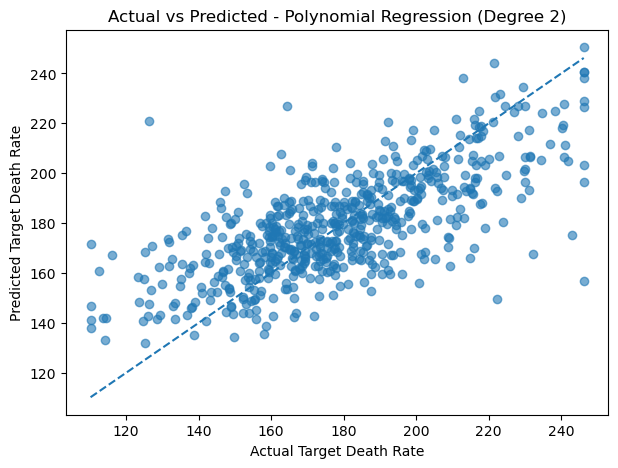

In [41]:
# Actual vs Predicted
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_poly2, alpha=0.6)

plt.xlabel("Actual Target Death Rate")
plt.ylabel("Predicted Target Death Rate")
plt.title("Actual vs Predicted - Polynomial Regression (Degree 2)")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.show()

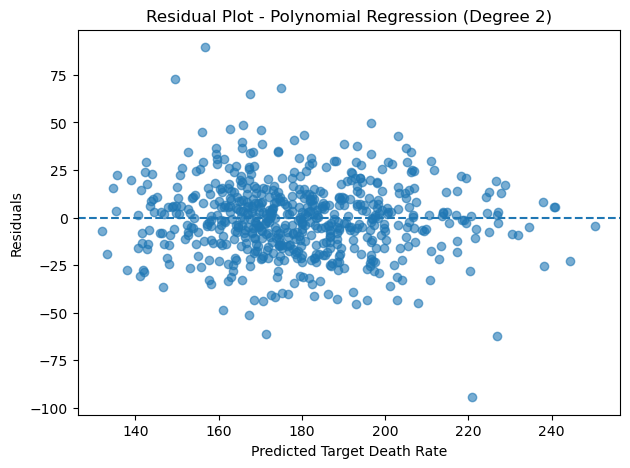

In [42]:
# Residual Plot
residuals = y_test - y_pred_poly2

plt.figure(figsize=(7, 5))

plt.scatter(y_pred_poly2, residuals, alpha=0.6)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Target Death Rate")
plt.ylabel("Residuals")
plt.title("Residual Plot - Polynomial Regression (Degree 2)")

plt.show()